In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Insurance claims data.csv")

In [3]:
df.head()

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,...,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
3,POL018146,5.2,0.4,44,C10,73430,A,M1,CNG,60Nm@3500rpm,...,No,No,No,Yes,No,No,No,Yes,0,0
4,POL049011,10.1,1.0,56,C13,5410,B2,M5,Diesel,200Nm@3000rpm,...,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  object 
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  object 
 7   model                             58592 non-null  object 
 8   fuel_type                         58592 non-null  object 
 9   max_torque                        58592 non-null  object 
 10  max_power                         58592 non-null  object 
 11  engine_type                       58592 non-null  object 
 12  airb

In [5]:
df.isna().sum().sum()

np.int64(0)

In [4]:
df['claim_status'].value_counts()

claim_status
0    54844
1     3748
Name: count, dtype: int64

In [5]:
(df['claim_status'].value_counts(normalize=True)*100).round(2)

claim_status
0    93.6
1     6.4
Name: proportion, dtype: float64

In [8]:
df_num_cols=df.select_dtypes(include=['int64','float64']).columns.to_list()

In [9]:
df_cat_cols=df.select_dtypes(include='object').columns.to_list()

In [13]:
df_num_cols

['subscription_length',
 'vehicle_age',
 'customer_age',
 'region_density',
 'airbags',
 'displacement',
 'cylinder',
 'turning_radius',
 'length',
 'width',
 'gross_weight',
 'ncap_rating',
 'claim_status']

In [14]:
df_cat_cols

['policy_id',
 'region_code',
 'segment',
 'model',
 'fuel_type',
 'max_torque',
 'max_power',
 'engine_type',
 'is_esc',
 'is_adjustable_steering',
 'is_tpms',
 'is_parking_sensors',
 'is_parking_camera',
 'rear_brakes_type',
 'transmission_type',
 'steering_type',
 'is_front_fog_lights',
 'is_rear_window_wiper',
 'is_rear_window_washer',
 'is_rear_window_defogger',
 'is_brake_assist',
 'is_power_door_locks',
 'is_central_locking',
 'is_power_steering',
 'is_driver_seat_height_adjustable',
 'is_day_night_rear_view_mirror',
 'is_ecw',
 'is_speed_alert']

In [6]:
df_num_cols.remove('claim_status')

In [10]:
df_cat_cols.remove('policy_id')

In [21]:
for cols in df_cat_cols:
  uni=df[cols].unique()
  print(f"{df[cols]} and is unique {uni} ")

0         C8
1         C2
2         C8
3        C10
4        C13
        ... 
58587     C5
58588     C3
58589     C8
58590     C8
58591    C12
Name: region_code, Length: 58592, dtype: object and is unique ['C8' 'C2' 'C10' 'C13' 'C7' 'C5' 'C3' 'C19' 'C9' 'C15' 'C6' 'C11' 'C1'
 'C14' 'C17' 'C12' 'C4' 'C21' 'C16' 'C18' 'C22' 'C20'] 
0        C2
1        C1
2        C2
3         A
4        B2
         ..
58587    B2
58588    C2
58589    B2
58590    B2
58591    B2
Name: segment, Length: 58592, dtype: object and is unique ['C2' 'C1' 'A' 'B2' 'B1' 'Utility'] 
0        M4
1        M9
2        M4
3        M1
4        M5
         ..
58587    M6
58588    M4
58589    M6
58590    M6
58591    M6
Name: model, Length: 58592, dtype: object and is unique ['M4' 'M9' 'M1' 'M5' 'M7' 'M6' 'M8' 'M3' 'M2' 'M10' 'M11'] 
0        Diesel
1        Diesel
2        Diesel
3           CNG
4        Diesel
          ...  
58587    Petrol
58588    Diesel
58589    Petrol
58590    Petrol
58591    Petrol
Name: fuel_type, 

In [3]:
cat_to_explore=['region_code','model','segment','fuel_type','transmission_type','steering_type']

In [4]:
for col in cat_to_explore:
  grp=df.groupby(col)['claim_status'].agg(['count','mean']).sort_values("count",ascending=False)
  grp['mean']=(grp["mean"]*100).round(2)
  print(grp.head(5))

             count  mean
region_code             
C8           13654  6.99
C2            7342  7.08
C5            6979  5.77
C3            6101  7.10
C14           3660  7.68
       count  mean
model             
M1     14948  6.14
M4     14018  6.43
M6     13776  6.82
M8      4173  5.85
M7      2940  6.84
         count  mean
segment             
B2       18314  6.86
A        17321  6.04
C2       14018  6.43
B1        4173  5.85
C1        3557  6.41
           count  mean
fuel_type             
Petrol     20532  6.64
CNG        20330  6.07
Diesel     17730  6.49
                   count  mean
transmission_type             
Manual             38181  6.39
Automatic          20411  6.42
               count  mean
steering_type             
Power          33502  6.20
Electric       23881  6.69
Manual          1209  6.04


In [11]:
binary_col=[c for c in df_cat_cols if set(df[c].unique())<={"Yes","No"}]

In [17]:
binary_col

['is_esc',
 'is_adjustable_steering',
 'is_tpms',
 'is_parking_sensors',
 'is_parking_camera',
 'is_front_fog_lights',
 'is_rear_window_wiper',
 'is_rear_window_washer',
 'is_rear_window_defogger',
 'is_brake_assist',
 'is_power_door_locks',
 'is_central_locking',
 'is_power_steering',
 'is_driver_seat_height_adjustable',
 'is_day_night_rear_view_mirror',
 'is_ecw',
 'is_speed_alert']

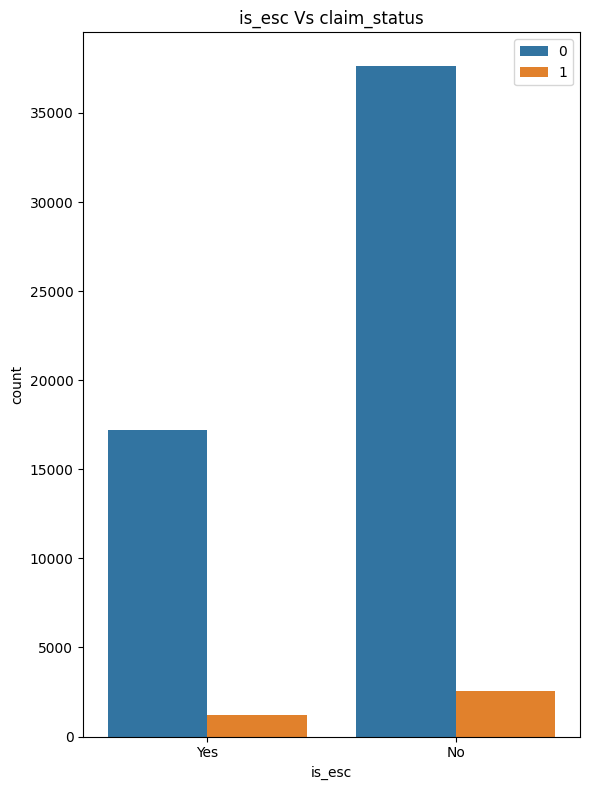

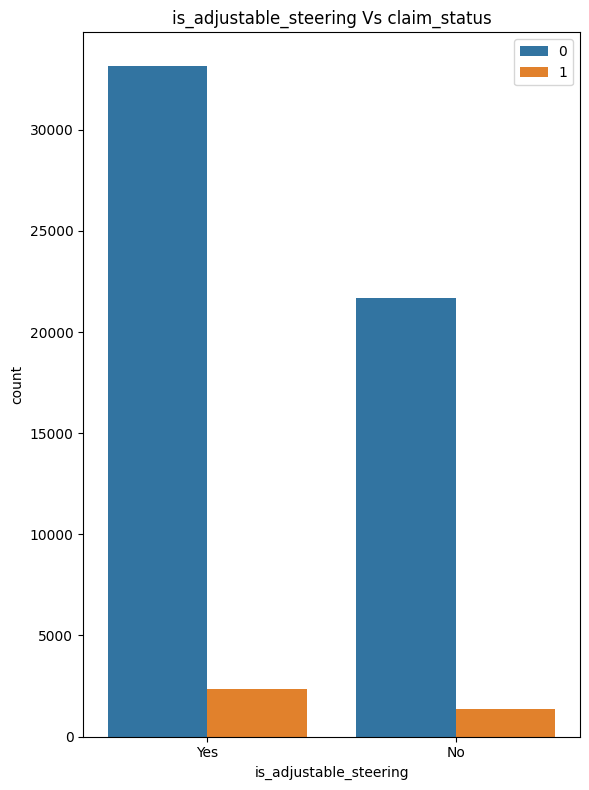

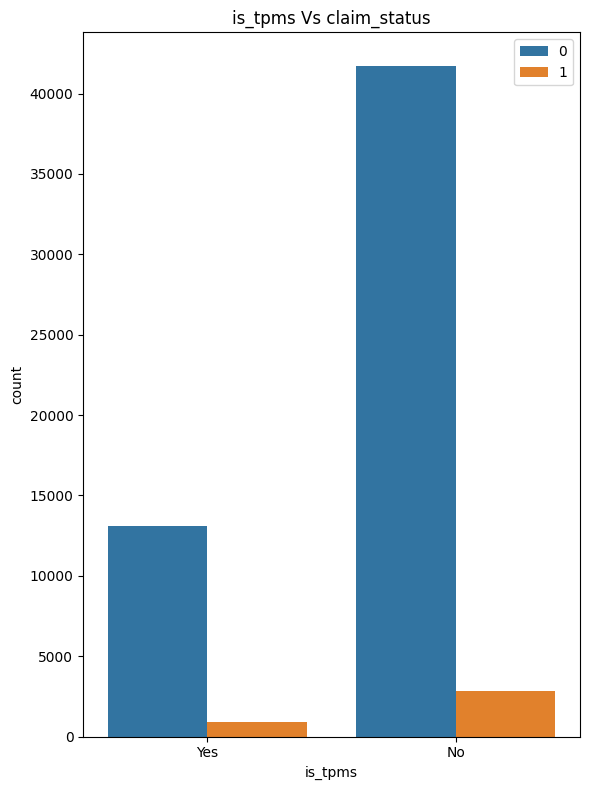

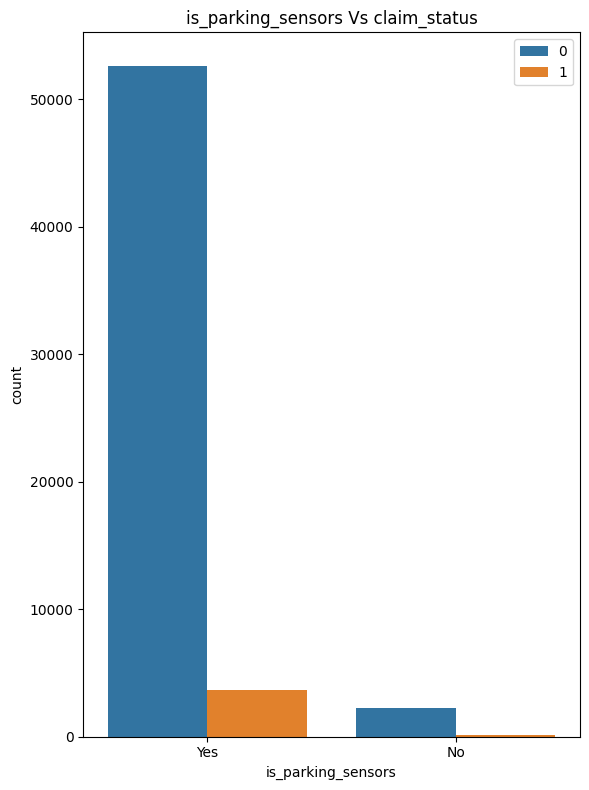

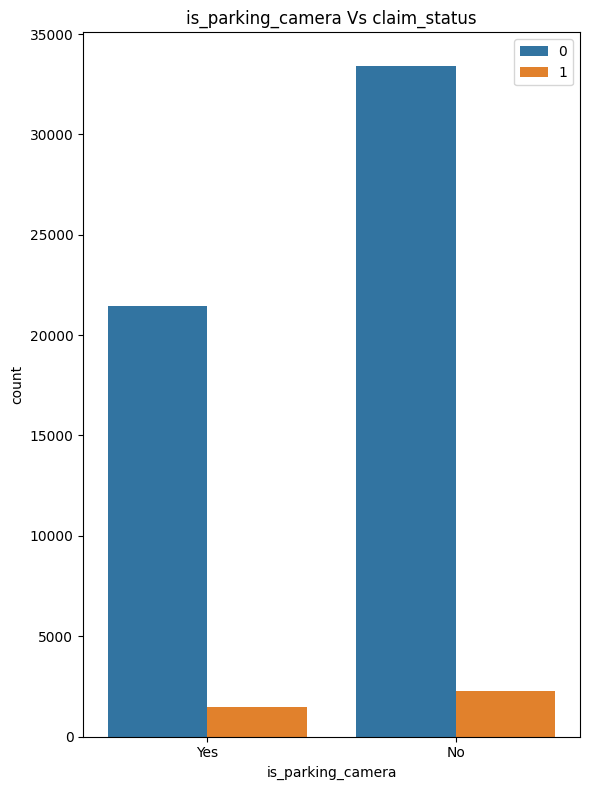

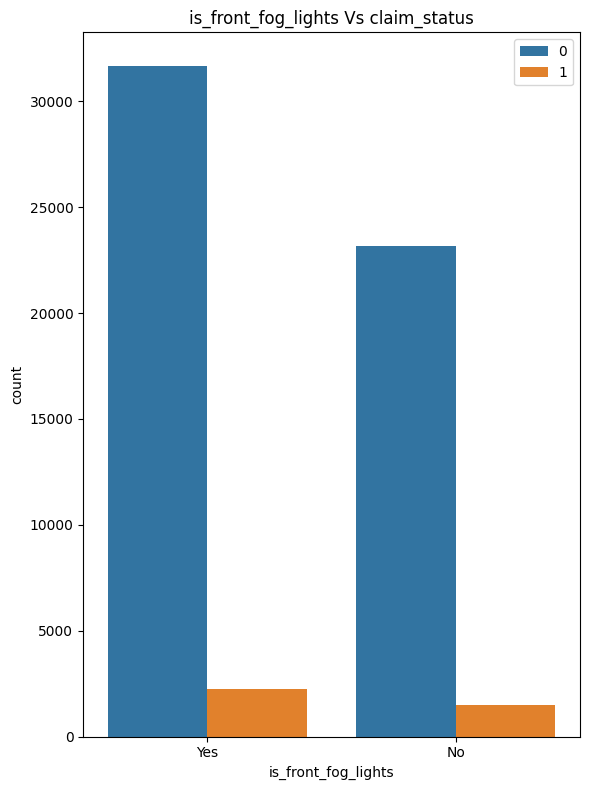

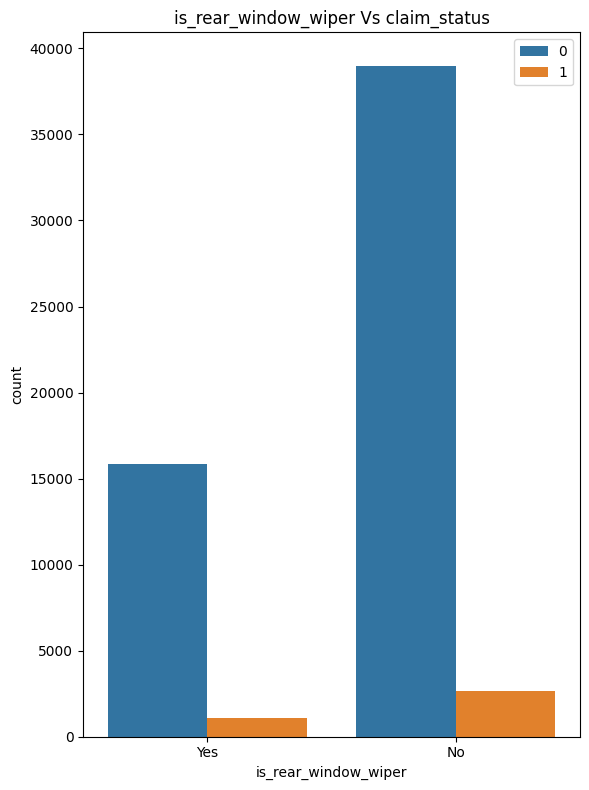

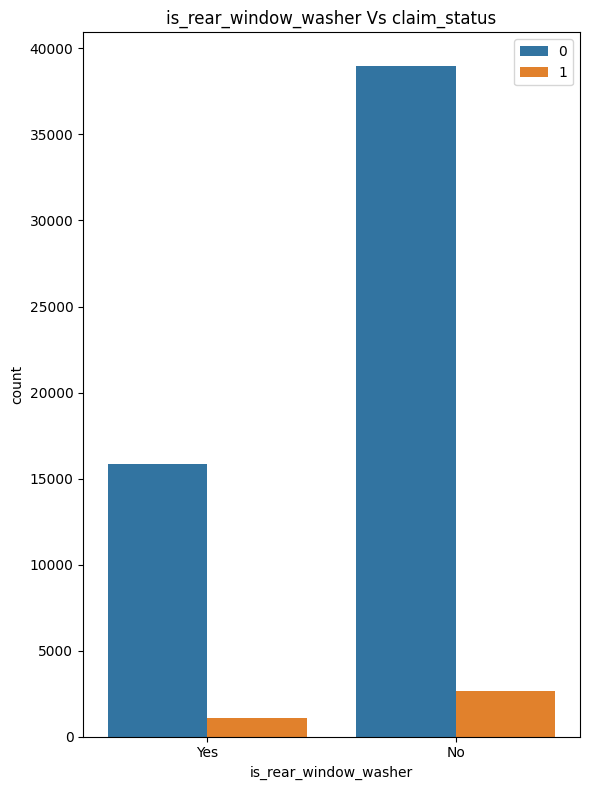

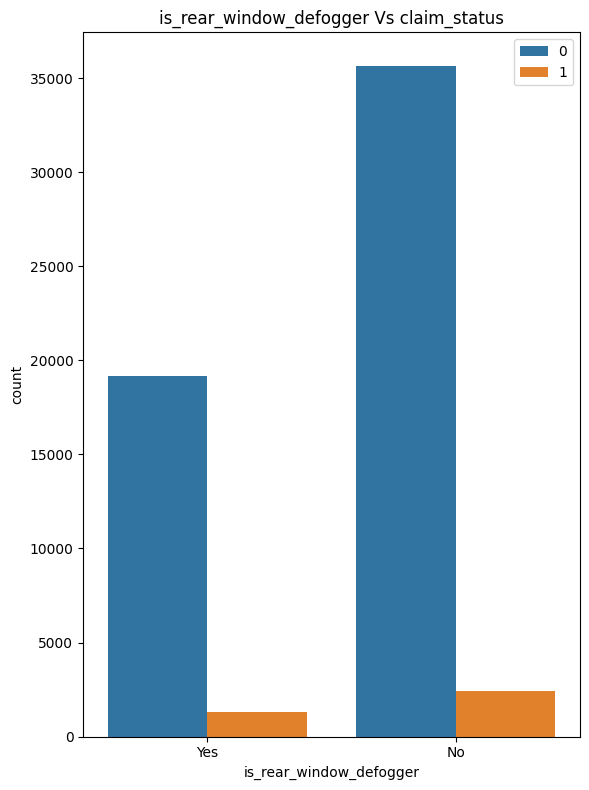

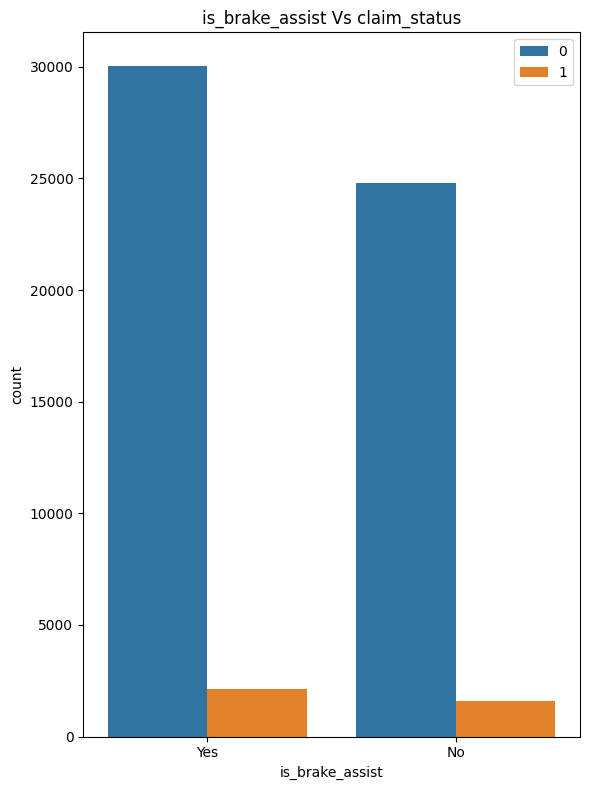

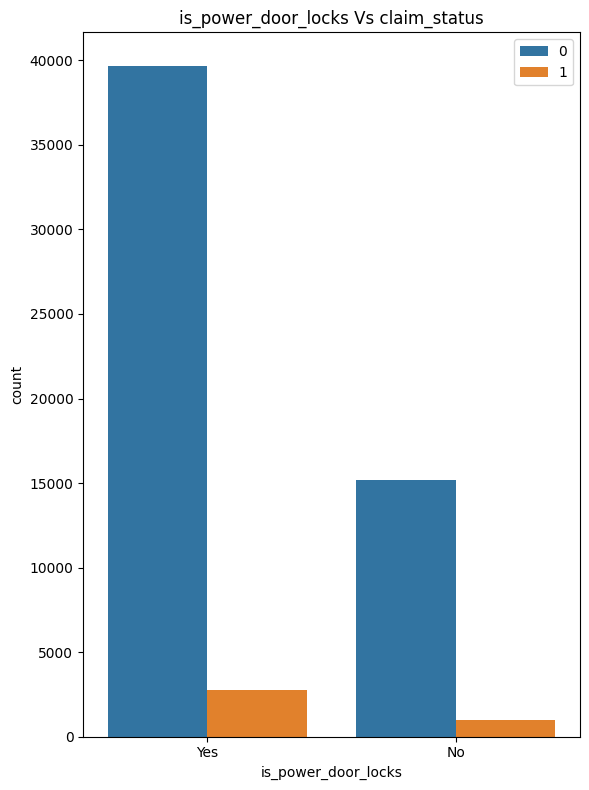

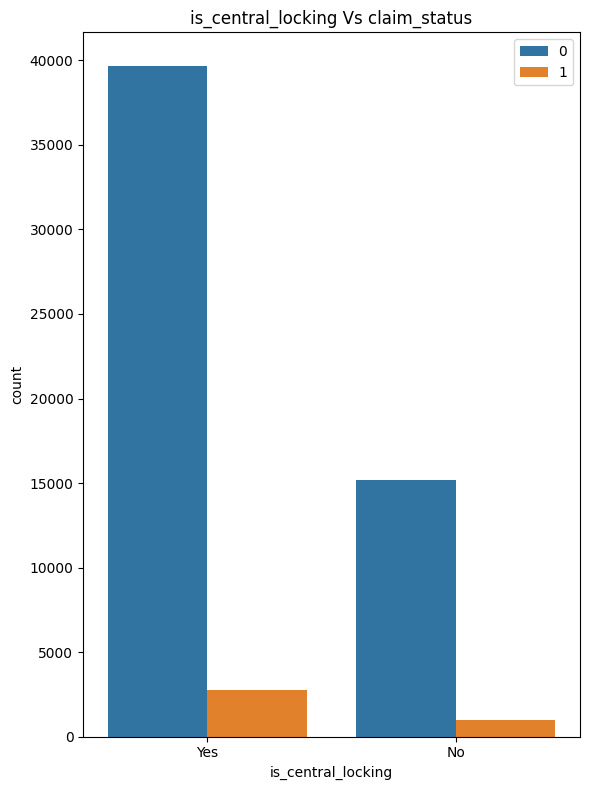

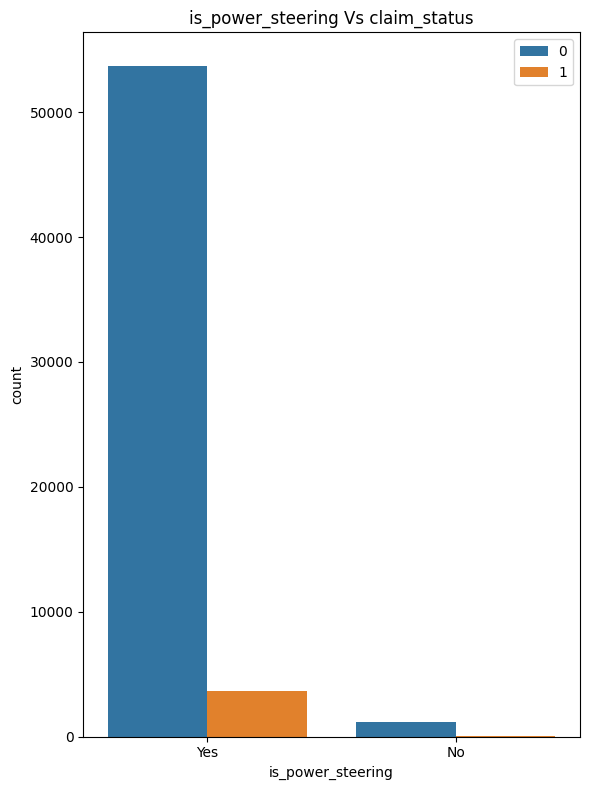

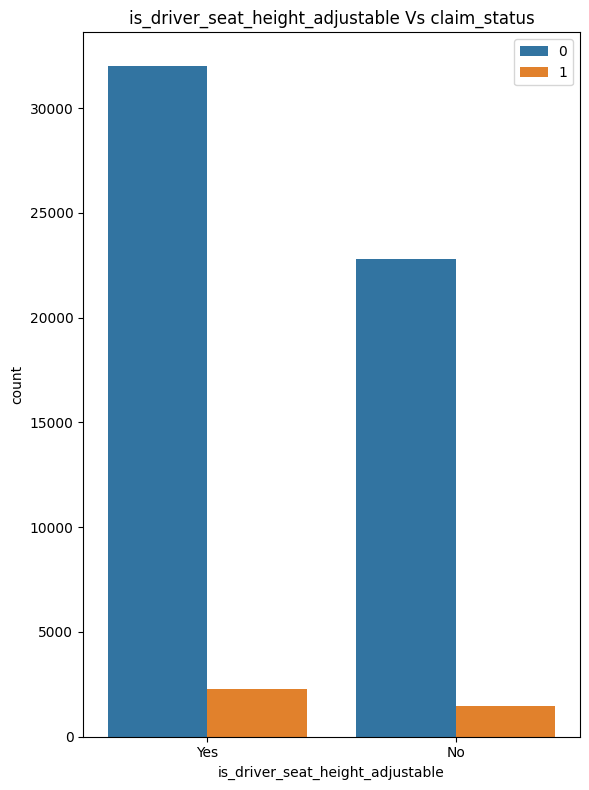

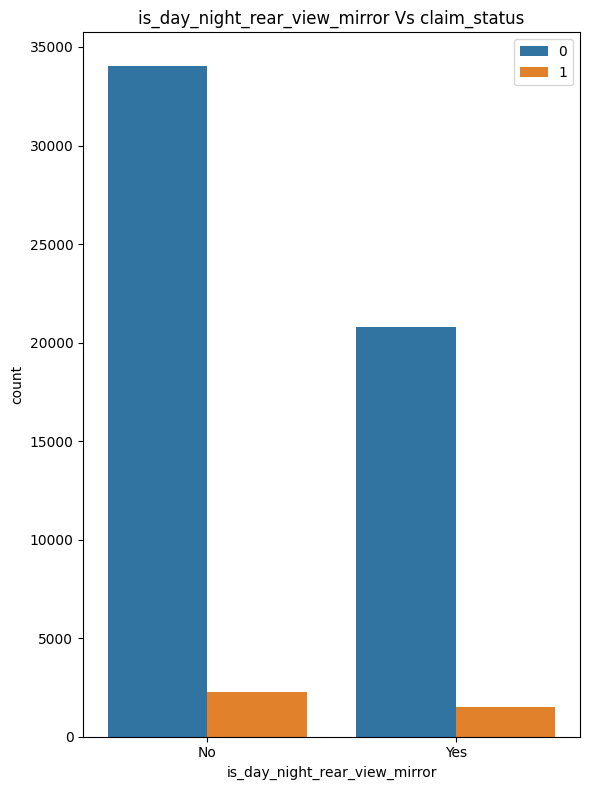

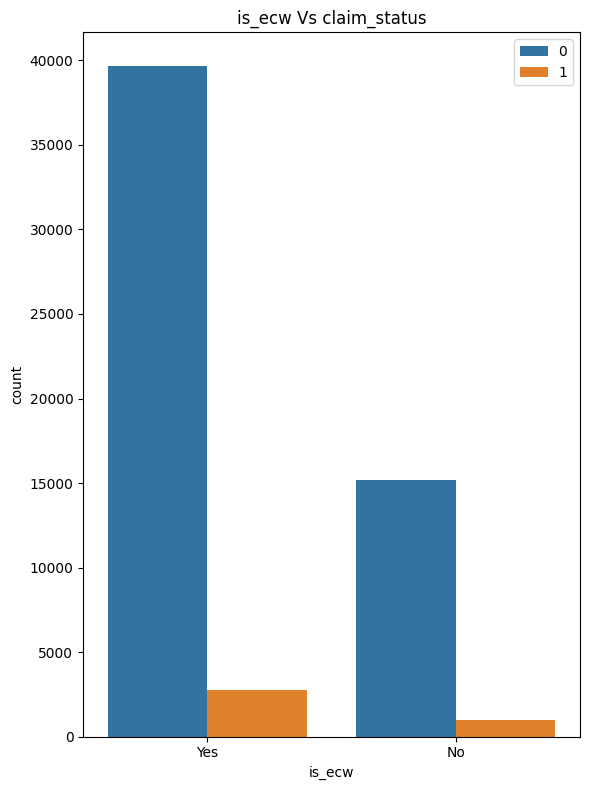

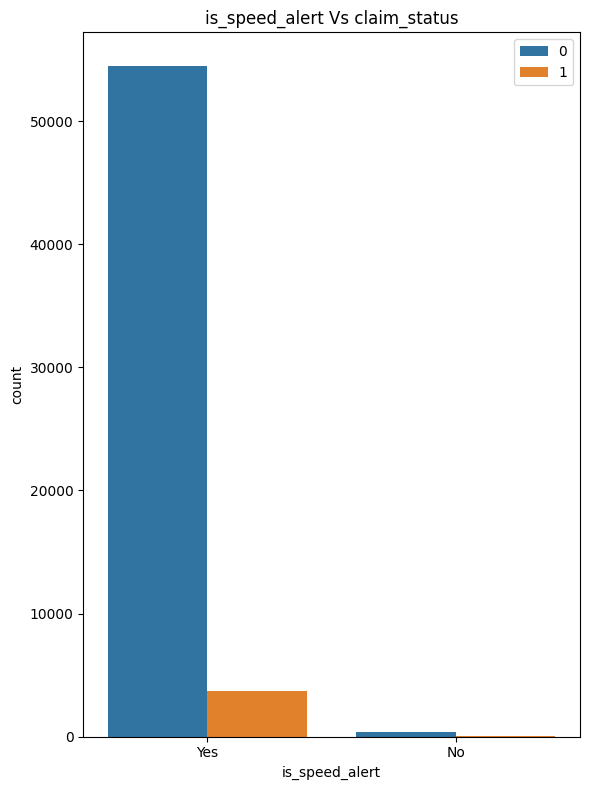

In [12]:
for i,col in enumerate(binary_col):
  plt.figure(i,figsize=(6,8))
  sns.countplot(data=df,x=col,hue=df['claim_status'])
  plt.title(f"{col} Vs claim_status")
  plt.legend()
  plt.tight_layout()
  plt.show()


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  object 
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  object 
 7   model                             58592 non-null  object 
 8   fuel_type                         58592 non-null  object 
 9   max_torque                        58592 non-null  object 
 10  max_power                         58592 non-null  object 
 11  engine_type                       58592 non-null  object 
 12  airb

In [12]:
df_num_cols

['subscription_length',
 'vehicle_age',
 'customer_age',
 'region_density',
 'airbags',
 'displacement',
 'cylinder',
 'turning_radius',
 'length',
 'width',
 'gross_weight',
 'ncap_rating']

In [13]:
df.groupby("claim_status")[df_num_cols].mean().T.round(2)

claim_status,0,1
subscription_length,6.03,7.36
vehicle_age,1.40,1.27
customer_age,44.78,45.41
region_density,18909.07,17623.82
airbags,3.14,3.16
displacement,1161.82,1170.18
cylinder,3.63,3.65
turning_radius,4.85,4.86
length,3849.95,3858.21
width,1671.94,1676.50


In [14]:
cat_to_explore

['region_code',
 'model',
 'segment',
 'fuel_type',
 'transmission_type',
 'steering_type']

In [19]:
for col in cat_to_explore:
  grp=df.groupby(col)['claim_status'].agg(["count","mean"]).sort_values("count",ascending=False)
  grp['mean']=(grp["mean"]*100).round(2)
  print(grp.head(10))

             count  mean
region_code             
C8           13654  6.99
C2            7342  7.08
C5            6979  5.77
C3            6101  7.10
C14           3660  7.68
C13           3423  5.70
C10           3155  4.69
C9            2734  4.97
C7            2167  5.03
C12           1589  5.48
       count  mean
model             
M1     14948  6.14
M4     14018  6.43
M6     13776  6.82
M8      4173  5.85
M7      2940  6.84
M3      2373  5.39
M9      2114  6.29
M5      1598  7.26
M10     1209  6.04
M2      1080  7.41
         count  mean
segment             
B2       18314  6.86
A        17321  6.04
C2       14018  6.43
B1        4173  5.85
C1        3557  6.41
Utility   1209  6.04
           count  mean
fuel_type             
Petrol     20532  6.64
CNG        20330  6.07
Diesel     17730  6.49
                   count  mean
transmission_type             
Manual             38181  6.39
Automatic          20411  6.42
               count  mean
steering_type             
Power      

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


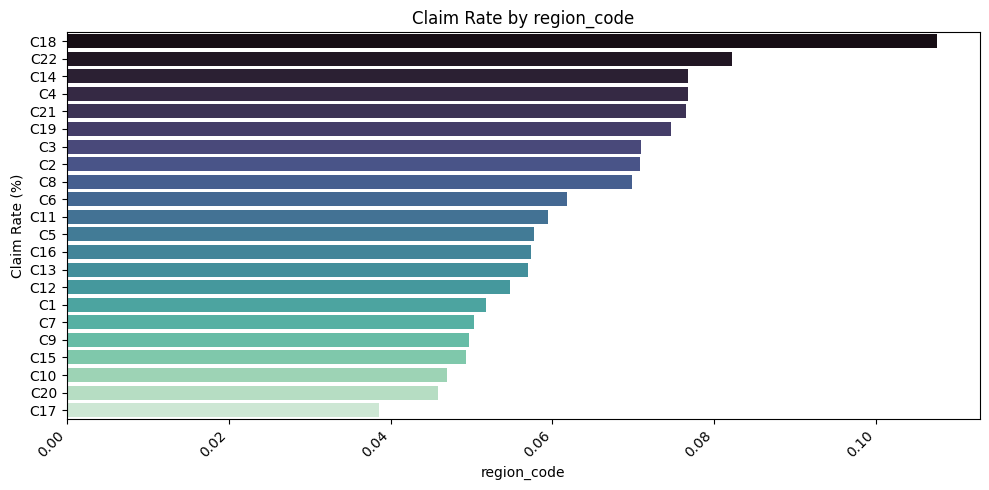

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


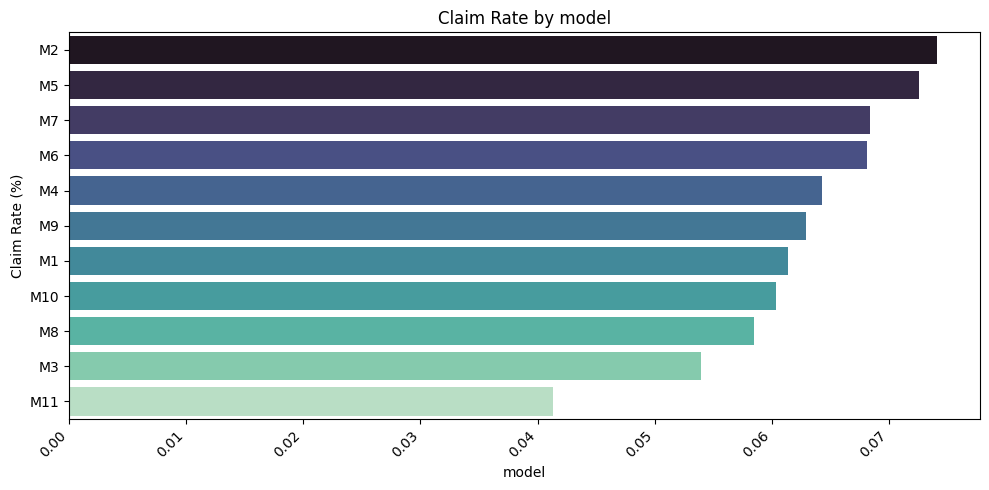

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


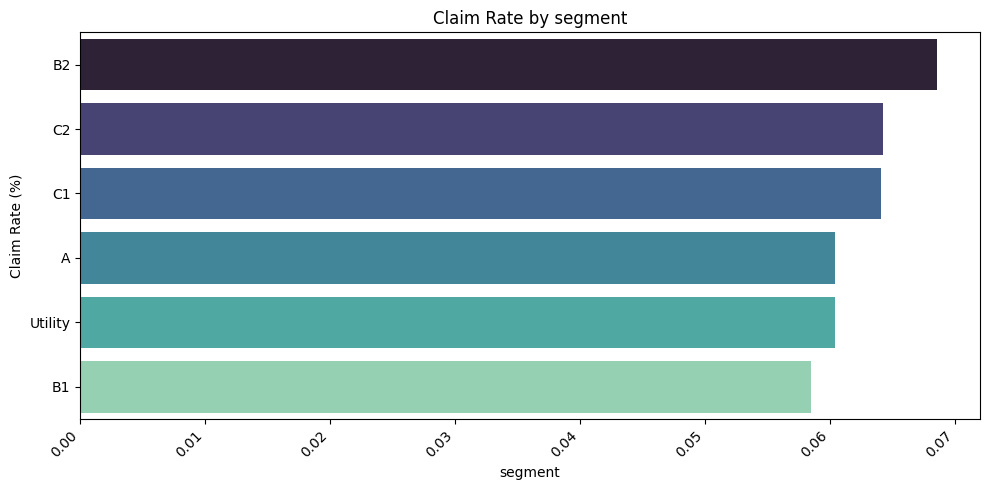

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


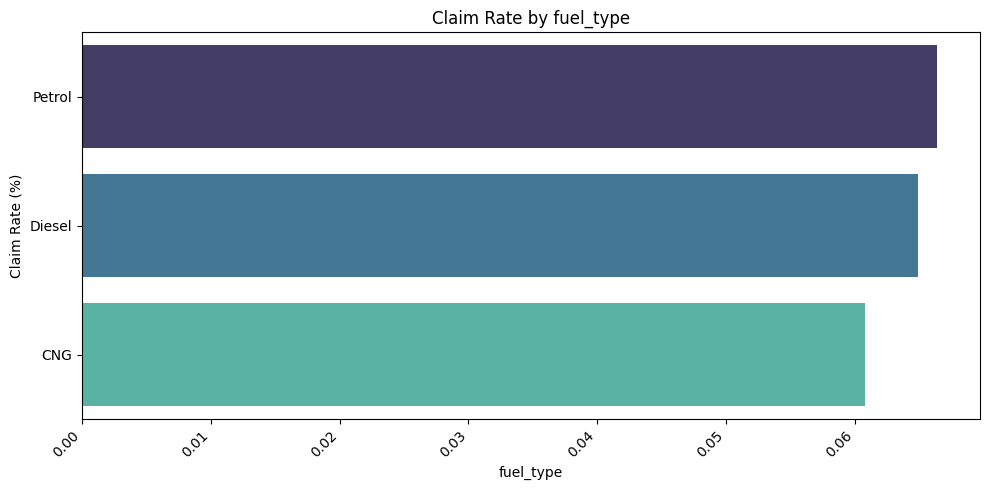

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


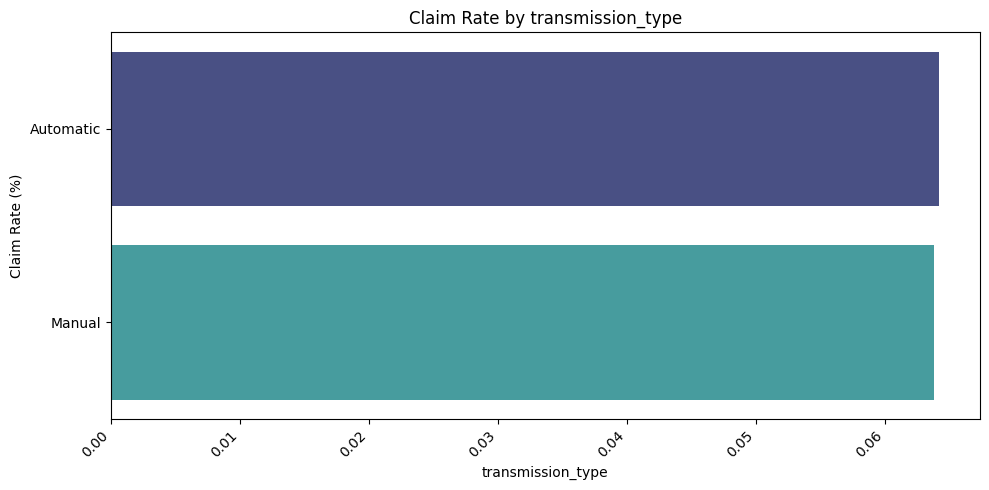

C:\Users\PC\AppData\Local\Temp\ipykernel_3148\518452949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grp.values, y=grp.index, palette='mako')


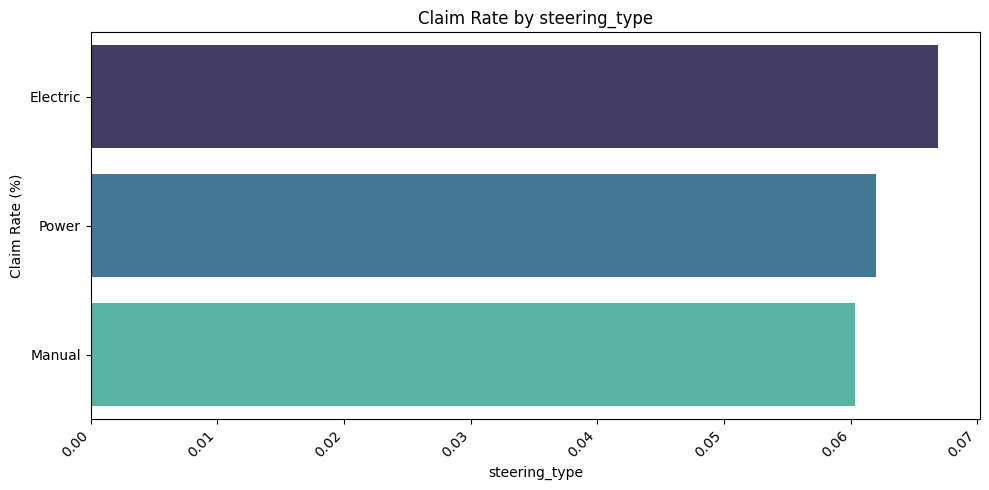

In [24]:
for col in cat_to_explore:
  plt.figure(figsize=(10, 5))
  grp=df.groupby(col)['claim_status'].mean().sort_values(ascending=False)
  sns.barplot(x=grp.values, y=grp.index, palette='mako')
  plt.title(f'Claim Rate by {col}')
  plt.xlabel(col)
  plt.ylabel('Claim Rate (%)')
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

In [27]:
corr_cols=df_num_cols+["claim_status"]

In [28]:
corr_cols

['subscription_length',
 'vehicle_age',
 'customer_age',
 'region_density',
 'airbags',
 'displacement',
 'cylinder',
 'turning_radius',
 'length',
 'width',
 'gross_weight',
 'ncap_rating',
 'claim_status']

In [30]:
corr=df[corr_cols].corr()

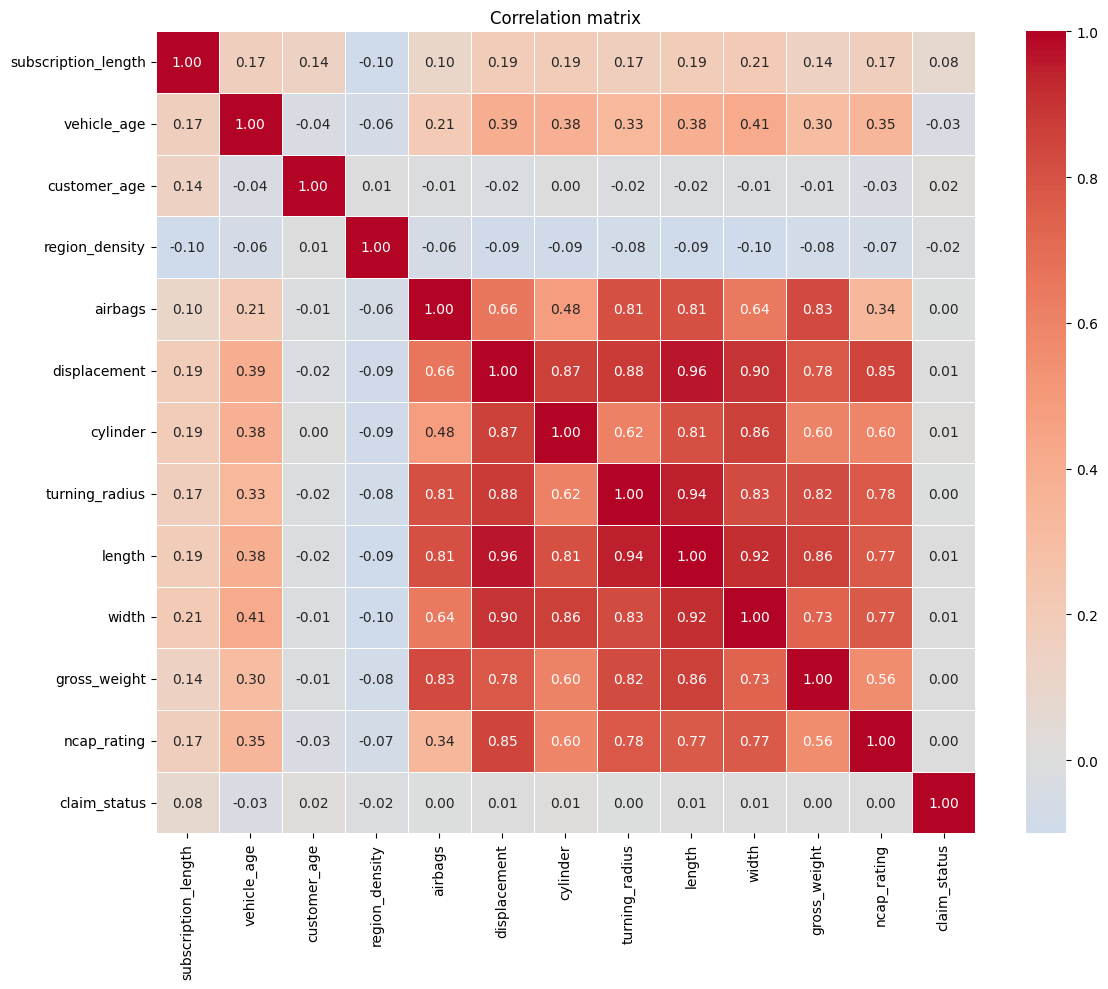

In [32]:
plt.figure(figsize=(12,10))
sns.heatmap(corr,fmt=".2f",annot=True,center=0,cmap="coolwarm",linewidths=0.5)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [14]:
drop_cols=['policy_id','segment',
'engine_type','fuel_type','max_torque',
'max_power','displacement', 'cylinder',
'displacement','cylinder',
 'turning_radius', 'length','width',
 'gross_weight','rear_brakes_type',
 'is_esc','is_adjustable_steering',
 'region_code','is_tpms',
 'is_parking_camera','is_rear_window_wiper',
 'is_rear_window_washer',
 'is_central_locking',
 'is_power_door_locks','is_rear_window_defogger','is_ecw','ncap_rating','airbags']

In [15]:
df_clean=df.drop(columns=drop_cols)

In [3]:
df.columns


Index(['policy_id', 'subscription_length', 'vehicle_age', 'customer_age',
       'region_code', 'region_density', 'segment', 'model', 'fuel_type',
       'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'steering_type', 'turning_radius', 'length',
       'width', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper',
       'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist',
       'is_power_door_locks', 'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'claim_status'],
      dtype='object')

In [10]:
df_clean

,subscription_length,vehicle_age,customer_age,region_density,model,is_parking_sensors,transmission_type,steering_type,is_front_fog_lights,is_rear_window_defogger,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status
0,9.3,1.2,41,8794,M4,Yes,Automatic,Power,Yes,Yes,Yes,Yes,Yes,No,Yes,0
1,8.2,1.8,35,27003,M9,Yes,Manual,Electric,Yes,Yes,No,Yes,Yes,Yes,Yes,0
2,9.5,0.2,44,8794,M4,Yes,Automatic,Power,Yes,Yes,Yes,Yes,Yes,No,Yes,0
3,5.2,0.4,44,73430,M1,Yes,Manual,Power,No,No,No,Yes,No,No,Yes,0
4,10.1,1.0,56,5410,M5,Yes,Manual,Electric,No,No,No,Yes,No,No,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,10.6,2.6,48,34738,M6,Yes,Manual,Electric,Yes,No,Yes,Yes,Yes,Yes,Yes,0
58588,2.3,2.2,37,4076,M4,Yes,Automatic,Power,Yes,Yes,Yes,Yes,Yes,No,Yes,0
58589,6.6,2.2,35,8794,M6,Yes,Manual,Electric,Yes,No,Yes,Yes,Yes,Yes,Yes,0
58590,4.1,3.6,44,8794,M6,Yes,Manual,Electric,Yes,No,Yes,Yes,Yes,Yes,Yes,0


In [15]:
df_clean.columns

Index(['subscription_length', 'vehicle_age', 'customer_age', 'region_density',
       'model', 'is_parking_sensors', 'transmission_type', 'steering_type',
       'is_front_fog_lights', 'is_brake_assist', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_speed_alert', 'claim_status'],
      dtype='object')

In [16]:
binary_final=['is_parking_sensors','is_front_fog_lights','is_brake_assist','is_power_steering','is_driver_seat_height_adjustable','is_day_night_rear_view_mirror','is_speed_alert']

In [17]:
for col in binary_final:
  df_clean[col]=df_clean[col].map({"Yes":1,"No":0})

In [23]:
df_clean

,subscription_length,vehicle_age,customer_age,region_density,model,is_parking_sensors,transmission_type,steering_type,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status
0,9.3,1.2,41,8794,M4,NaN,Automatic,Power,NaN,1,1,1,0,1,0
1,8.2,1.8,35,27003,M9,NaN,Manual,Electric,NaN,0,1,1,1,1,0
2,9.5,0.2,44,8794,M4,NaN,Automatic,Power,NaN,1,1,1,0,1,0
3,5.2,0.4,44,73430,M1,NaN,Manual,Power,NaN,0,1,0,0,1,0
4,10.1,1.0,56,5410,M5,NaN,Manual,Electric,NaN,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,10.6,2.6,48,34738,M6,NaN,Manual,Electric,NaN,1,1,1,1,1,0
58588,2.3,2.2,37,4076,M4,NaN,Automatic,Power,NaN,1,1,1,0,1,0
58589,6.6,2.2,35,8794,M6,NaN,Manual,Electric,NaN,1,1,1,1,1,0
58590,4.1,3.6,44,8794,M6,NaN,Manual,Electric,NaN,1,1,1,1,1,0


In [24]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 15 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subscription_length               58592 non-null  float64
 1   vehicle_age                       58592 non-null  float64
 2   customer_age                      58592 non-null  int64  
 3   region_density                    58592 non-null  int64  
 4   model                             58592 non-null  object 
 5   is_parking_sensors                0 non-null      float64
 6   transmission_type                 58592 non-null  object 
 7   steering_type                     58592 non-null  object 
 8   is_front_fog_lights               0 non-null      float64
 9   is_brake_assist                   58592 non-null  int64  
 10  is_power_steering                 58592 non-null  int64  
 11  is_driver_seat_height_adjustable  58592 non-null  int64  
 12  is_d

In [18]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()

df_clean[['transmission_type', 'steering_type', 'model']] = encoder.fit_transform(
    df_clean[['transmission_type', 'steering_type', 'model']]
)

print(df_clean)

       subscription_length  vehicle_age  ...  is_speed_alert  claim_status
0                      9.3          1.2  ...               1             0
1                      8.2          1.8  ...               1             0
2                      9.5          0.2  ...               1             0
3                      5.2          0.4  ...               1             0
4                     10.1          1.0  ...               1             0
...                    ...          ...  ...             ...           ...
58587                 10.6          2.6  ...               1             0
58588                  2.3          2.2  ...               1             0
58589                  6.6          2.2  ...               1             0
58590                  4.1          3.6  ...               1             0
58591                  3.1          0.4  ...               1             0

[58592 rows x 15 columns]


In [26]:
df_clean.head()


,subscription_length,vehicle_age,customer_age,region_density,model,is_parking_sensors,transmission_type,steering_type,is_front_fog_lights,is_brake_assist,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_speed_alert,claim_status
0,9.3,1.2,41,8794,5.0,NaN,0.0,2.0,NaN,1,1,1,0,1,0
1,8.2,1.8,35,27003,10.0,NaN,1.0,0.0,NaN,0,1,1,1,1,0
2,9.5,0.2,44,8794,5.0,NaN,0.0,2.0,NaN,1,1,1,0,1,0
3,5.2,0.4,44,73430,0.0,NaN,1.0,2.0,NaN,0,1,0,0,1,0
4,10.1,1.0,56,5410,6.0,NaN,1.0,0.0,NaN,0,1,0,0,1,0


In [35]:
from itertools import permutations,combinations

In [37]:
data=[1,2,3,4]
c=0
prem=permutations(data,3)
con=combinations(data,3)
for i in prem:
 print(i)
 c+=1
 print(c)
 for i in con:
  print(i)

(1, 2, 3)
1
(1, 2, 3)
(1, 2, 4)
(1, 3, 4)
(2, 3, 4)
(1, 2, 4)
2
(1, 3, 2)
3
(1, 3, 4)
4
(1, 4, 2)
5
(1, 4, 3)
6
(2, 1, 3)
7
(2, 1, 4)
8
(2, 3, 1)
9
(2, 3, 4)
10
(2, 4, 1)
11
(2, 4, 3)
12
(3, 1, 2)
13
(3, 1, 4)
14
(3, 2, 1)
15
(3, 2, 4)
16
(3, 4, 1)
17
(3, 4, 2)
18
(4, 1, 2)
19
(4, 1, 3)
20
(4, 2, 1)
21
(4, 2, 3)
22
(4, 3, 1)
23
(4, 3, 2)
24


In [19]:
from sklearn.model_selection import train_test_split
x=df_clean.drop(columns=['claim_status'])
y=df_clean['claim_status']

In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y)

In [25]:
neg_count=(y_train==0).sum()
pos_count=(y_train==1).sum()
print(neg_count)
print(pos_count)
scale_pos_weight=neg_count/pos_count
scale_pos_weight

43875
2998


np.float64(14.634756504336224)

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [27]:
dt=DecisionTreeClassifier(max_depth=4,class_weight="balanced")

In [29]:
model_dt=dt.fit(x_train,y_train)
model_dt

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [30]:
rf=RandomForestClassifier(n_estimators=300,max_depth=8,class_weight="balanced",n_jobs=-1)

In [31]:
model_rf=rf.fit(x_train,y_train)

In [32]:
model_rf

,n_estimators,300
,criterion,'gini'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
xgb=XGBClassifier(n_estimator=300,max_depth=4,n_jobs=-1,learning_rate=0.05,scale_pos_weight=scale_pos_weight,eval_metric='logloss')

In [34]:
model_xgb=xgb.fit(x_train,y_train)

In [35]:
model_xgb

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [36]:
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score

In [42]:
model=[('Decision Tree',dt),('random_forest',rf),('xgboost',xgb)]

In [43]:
auc_score={}
for name,model in model:
  y_pred=model.predict(x_test)
  probs=model.predict_proba(x_test)[:,1]
  auc=roc_auc_score(y_test,probs)
  auc_score[name]=auc
  print(f"------------{name}-----")
  print(classification_report(y_test,y_pred))
  print("ROC-AUC",round(auc,4))

------------Decision Tree-----
              precision    recall  f1-score   support

           0       0.96      0.63      0.76     10969
           1       0.10      0.59      0.17       750

    accuracy                           0.62     11719
   macro avg       0.53      0.61      0.46     11719
weighted avg       0.90      0.62      0.72     11719

ROC-AUC 0.6388
------------random_forest-----
              precision    recall  f1-score   support

           0       0.96      0.60      0.74     10969
           1       0.10      0.63      0.17       750

    accuracy                           0.60     11719
   macro avg       0.53      0.61      0.45     11719
weighted avg       0.90      0.60      0.70     11719

ROC-AUC 0.6545
------------xgboost-----
              precision    recall  f1-score   support

           0       0.96      0.53      0.68     10969
           1       0.09      0.70      0.16       750

    accuracy                           0.54     11719
   macro av

In [53]:
best_name=max(auc_score,key=auc_score.get)
best_model=best_name
auc_score[best_model]

0.6554035311635822

In [49]:
best_name


'xgboost'

In [55]:
import joblib

In [58]:
joblib.dump(best_model,"claim_model.pkl")
joblib.dump(x_train.columns.to_list(),"model_columns.pkl")
joblib.dump(sorted(df_clean["model"].unique().tolist()),"model_options.pkl")

['model_options.pkl']